In [1]:
import numpy as np
import xarray as xr
import rioxarray  # noqa: F401
import matplotlib.pyplot as plt
from seaborn import set_theme
from rasterio.enums import Resampling
set_theme()

import sys
import os
from pathlib import Path

# import from this repo
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.taus import decorrelation_temporal_model, decorrelation_temporal_model_snow

In [2]:
data_dir = "../data/"
res = '80m'
track = 19

coh = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/coherence_{res}.zarr', consolidated=False).load()
coh.pair.values

array(['20251123_20251205', '20251123_20251217', '20251123_20251229',
       '20251123_20260110', '20251123_20260122', '20251123_20260203',
       '20251123_20260215', '20251123_20260227', '20251123_20260311',
       '20251123_20260323', '20251123_20260404', '20251123_20260416',
       '20251123_20260428', '20251123_20260510', '20251123_20260522',
       '20251123_20260603', '20251123_20260615', '20251123_20260627',
       '20251123_20260709', '20251123_20260721', '20251123_20260814',
       '20251123_20260826', '20251123_20260919', '20251123_20261001',
       '20251205_20251217', '20251205_20251229', '20251205_20260110',
       '20251205_20260122', '20251205_20260203', '20251205_20260215',
       '20251205_20260227', '20251205_20260311', '20251205_20260323',
       '20251205_20260404', '20251205_20260416', '20251205_20260428',
       '20251205_20260510', '20251205_20260522', '20251205_20260603',
       '20251205_20260615', '20251205_20260627', '20251205_20260709',
       '20251205_202

In [3]:
coh = coh.sel(pair=['20260215_20260227', '20260110_20260122', '20260122_20260203'])
coh = coh.set_coords('spatial_ref')
coh

<xarray.Dataset> Size: 23MB
Dimensions:                     (pair: 3, y: 566, x: 433)
Coordinates:
  * pair                        (pair) <U17 204B '20260215_20260227' ... '202...
    start                       (pair) datetime64[ns] 24B 2026-02-15T05:11:41...
    end                         (pair) datetime64[ns] 24B 2026-02-27T05:11:42...
  * y                           (y) float64 5kB 4.324e+06 ... 4.279e+06
  * x                           (x) float64 3kB 3.151e+05 ... 3.496e+05
    spatial_ref                 int64 8B 0
Data variables:
    gamma_spatial               (pair, y, x) float32 3MB nan nan nan ... nan nan
    canopy_2021                 (y, x) float32 980kB 44.0 26.0 ... 50.0 56.0
    coherence_true              (pair, y, x) float64 6MB 0.1811 ... 0.7319
    gamma_temporal              (pair, y, x) float32 3MB nan nan nan ... nan nan
    gamma_temporal_uncorrected  (pair, y, x) float32 3MB nan nan nan ... nan nan
    coherence                   (pair, y, x) float32 3MB 0.189 0.2794 ... 0.7323
    elevation                   (y, x) float32 980kB 3.169e+03 ... 2.901e+03
    gamma_thermal               (pair, y, x) float32 3MB nan nan nan ... nan nan
Attributes:
    crs:                   EPSG:32613
    track:                 19
    frame:                 21
    utc_offset_hours:      -7
    spatial_res:           3
    wavelength:            0.24
    incidence_to_radians:  1
    aso:                   None

In [4]:
inc_path = data_dir + 'lia/lia_track019_frame021_10m.tif'

In [5]:
aso_path = data_dir + 'aso/er_20260318/ASO_EastRiver_2026Mar18_snowdepth_3m.tif'
aso_date = '2026-03-18'

In [6]:
aso_3m = rioxarray.open_rasterio(aso_path, masked=True, chunks={'x': 2048, 'y': 2048}).squeeze(drop=True)
aso_9m = aso_3m.rio.reproject(coh.rio.crs, resampling=Resampling.average, resolution=9)
aso_9m = aso_9m / aso_9m.max()

In [7]:
sx_path = data_dir + 'wind_exposure/wind_exposure_10m.zarr'

/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/google/api_core/_python_version_support.py:255: FutureWarning: You are using a Python version (3.11.15) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


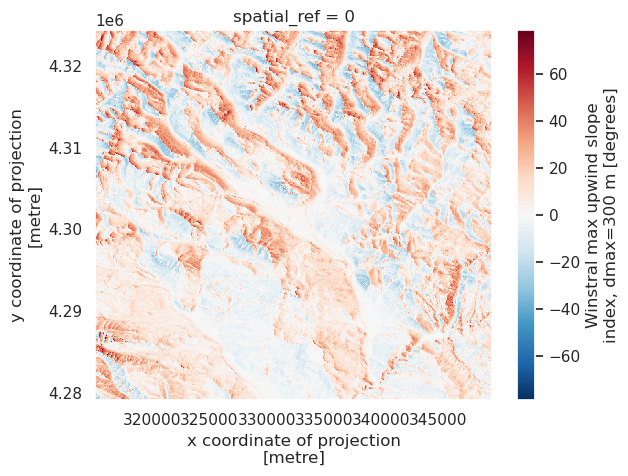

In [8]:
sx = xr.open_dataset(sx_path)
sx = sx.set_coords('spatial_ref')
sx = sx.rio.reproject_match(coh)
sx['sx_300'].plot()

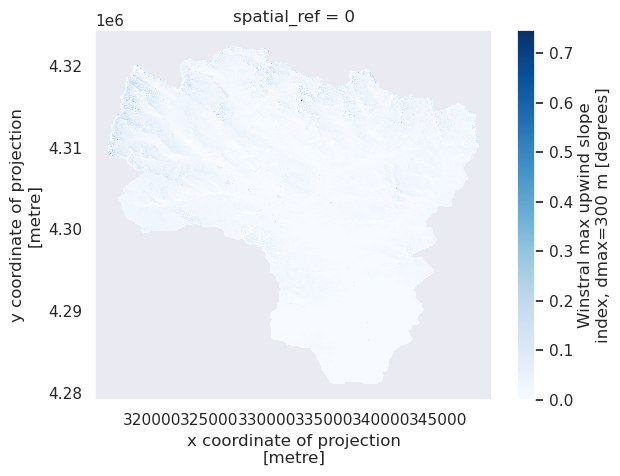

In [142]:
swe_dist = aso_9m.rio.reproject_match(coh)
swe_dist = ((sx['sx_300'] / sx['sx_300'].max() + 1) / 2) 
swe_dist = swe_dist * aso_9m.rio.reproject_match(coh)
swe_dist.plot(cmap='Blues')

In [143]:
valid = (~swe_dist.isnull())

In [161]:
# get swe accum for the two flights 
swe_light = 10 # mm
swe_mid = 25 # mm
swe_heavy = 200 # mm

# calculate distributed snow depth 
swe_by_pair = {
    '20260215_20260227': swe_heavy,
    '20260110_20260122': swe_light,
    '20260122_20260203': swe_mid, 
}

# 1-D array aligned to coh's pair coordinate (NaN for any pair not in the dict)
swe_scale = xr.DataArray(
    [swe_by_pair.get(p, np.nan) for p in coh.pair.values],
    coords={'pair': coh.pair},
    dims='pair',
)

# print(swe_scale * swe_dist)
coh['swe'] = swe_scale * swe_dist 

# get deep_snow mask 
deep_snow = 5 # mm
snow_mask = coh['swe'] > deep_snow

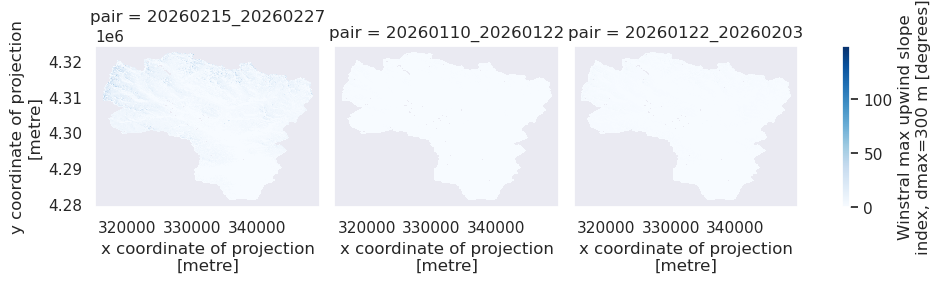

In [162]:
coh['swe'].plot(col='pair', cmap='Blues')

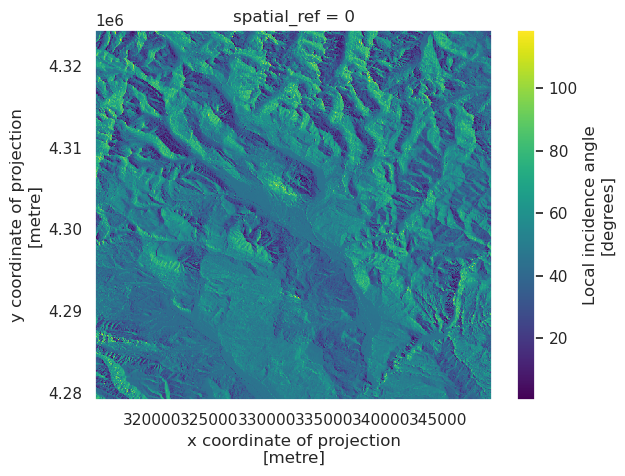

In [163]:
# load incidence angle file 
inc_10m = rioxarray.open_rasterio(inc_path, masked=True, chunks={'x': 2048, 'y': 2048}).squeeze(drop=True)
inc = inc_10m.rio.reproject_match(coh)
inc.plot()

In [164]:
coh['inc'] = inc

In [165]:
# get high_angle mask 
high_inc = 70 

inc_mask = (coh['inc'] > high_inc) 

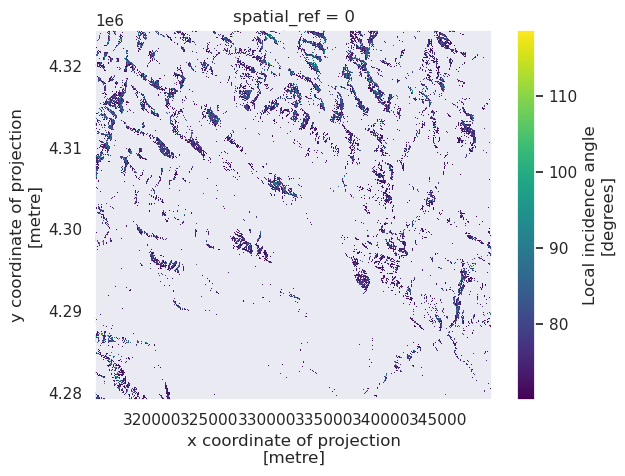

In [166]:
coh['inc'].where(inc_mask).plot()

In [167]:
# calculate average coherence over all 4 categories 
deep_steep = coh['gamma_temporal'].where((inc_mask & snow_mask & valid))
deep_shallow = coh['gamma_temporal'].where((~inc_mask & snow_mask & valid))
shallow_shallow = coh['gamma_temporal'].where((~inc_mask & ~snow_mask & valid))
shallow_steep = coh['gamma_temporal'].where((inc_mask & ~snow_mask & valid))

In [168]:
print(f'\t\t Deep snow \t Shallow snow')
print(f'Steep angle \t {deep_steep.mean().values:.5f} \t {shallow_steep.mean().values:.5f}')
print(f'Shallow angle \t {deep_shallow.mean().values:.5f} \t {shallow_shallow.mean().values:.5f}')

		 Deep snow 	 Shallow snow
Steep angle 	 0.16625 	 0.39682
Shallow angle 	 0.28354 	 0.57987


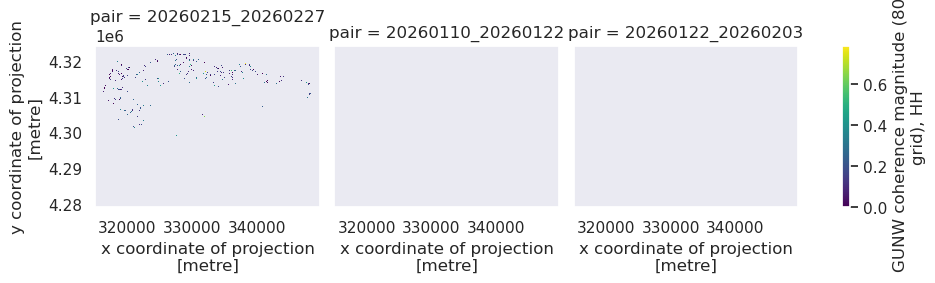

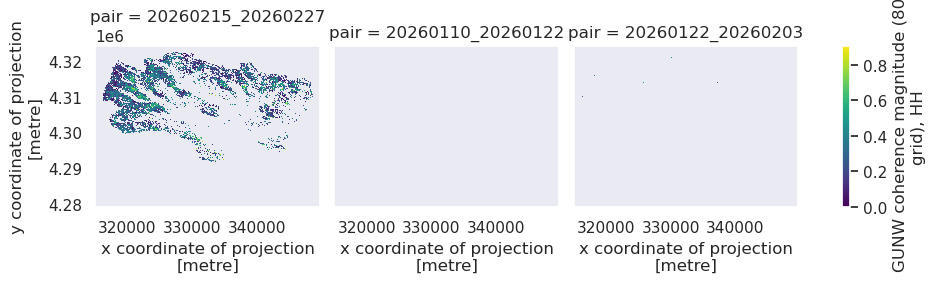

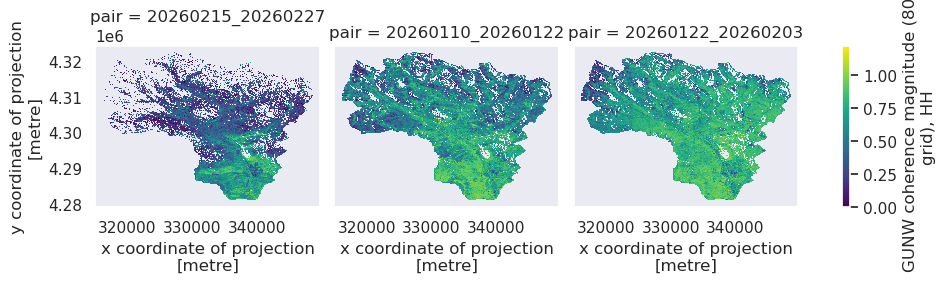

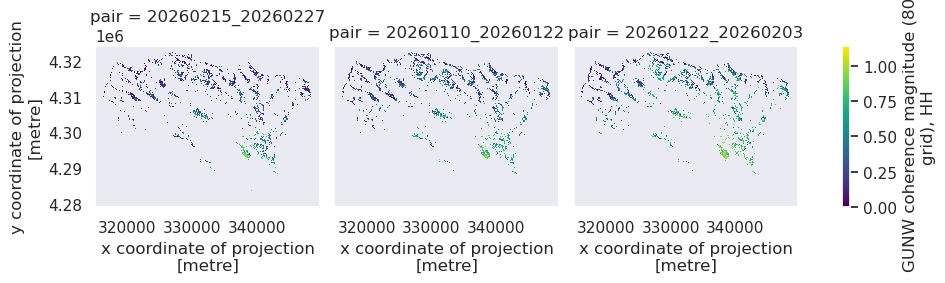

In [169]:
for subset in [deep_steep, deep_shallow, shallow_shallow, shallow_steep] : 
    # print((~subset.isnull()))
    subset.plot(col='pair')

In [170]:
k = 2 # mm 
m = 1/3
ex = '20260110_20260122'
ex = '20260122_20260203'
# ex = '20260215_20260227'

In [171]:
swe_term = (100 / coh['swe'].sel(pair=ex))
swe_term = np.exp(-k * coh['swe'].sel(pair=ex))

print(f'Min: {np.nanmin(swe_term.values)}')
print(f'Max: {np.nanmax(swe_term.values)}')
print(f'Std: {np.nanstd(swe_term.values)}')

Min: 6.167928539271871e-17
Max: 1.0
Std: 0.32491447172274784


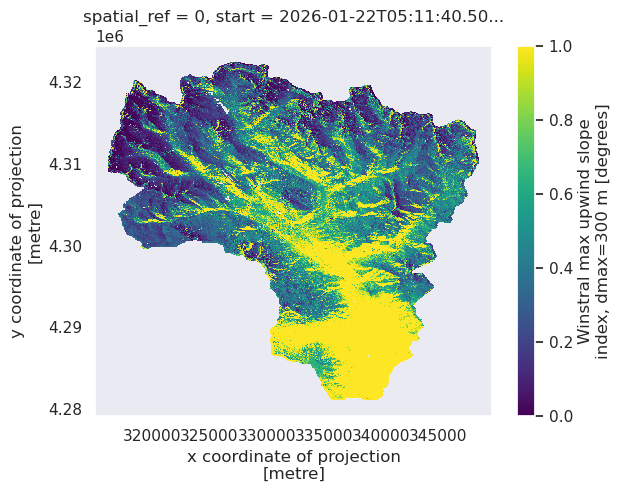

In [172]:
swe_term.plot()

In [173]:
decor = k * swe_term * np.sin(np.deg2rad(coh['inc']/2))
decor = np.sin(np.deg2rad(coh['inc']/2)) * np.exp((-1/k) * coh['swe'].sel(pair=ex) * (np.sin(np.deg2rad(coh['inc']/2))**m))


In [219]:
def gamma_snow(swe, theta, k=100, s0=5, p=5):
    a = np.cos(np.deg2rad(theta) / 2.0) 
    w = 1.0 - np.exp(-swe / s0) 
    # w = 1
    return np.exp(-swe / k) * (a ** (p * w)) 

decor = gamma_snow(coh['swe'], coh['inc'])

In [220]:
print(f'\t\t 10 mm SWE \t 50 mm SWE \t 150 mm SWE')
print(f'10 deg \t\t {gamma_snow(10, 10):.5f} \t {gamma_snow(50, 10):.5f}\t {gamma_snow(150, 10):.5f}')
print(f'45 deg \t\t {gamma_snow(10, 45):.5f} \t {gamma_snow(50, 45):.5f}\t {gamma_snow(150, 45):.5f}')
print(f'100 deg \t {gamma_snow(10, 100):.5f} \t {gamma_snow(50, 100):.5f}\t {gamma_snow(150, 100):.5f}')

		 10 mm SWE 	 50 mm SWE 	 150 mm SWE
10 deg 		 0.89005 	 0.59508	 0.21892
45 deg 		 0.64256 	 0.40826	 0.15019
100 deg 	 0.13390 	 0.06656	 0.02448


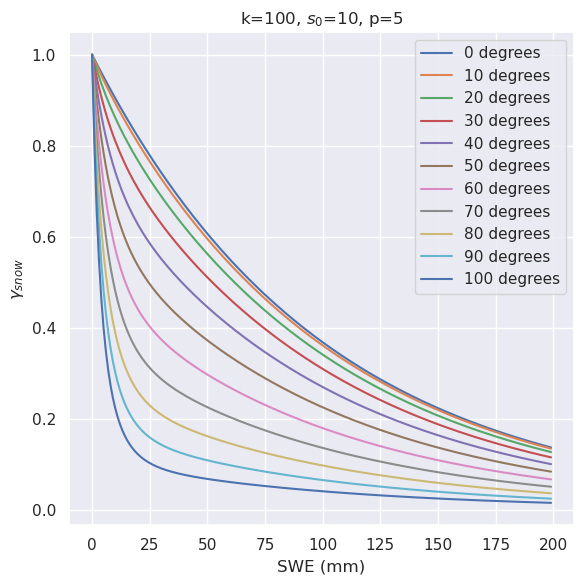

In [228]:
incs = np.arange(0, 101, 10)
swes = np.arange(0, 200, 1)

k = 100 # mm swe
p = 5
s0 = 10 # mm swe

fig, ax = plt.subplots(figsize=(6, 6))

ax.set_title(f'k={k}, $s_0$={s0}, p={p}')

for i in incs: 
    ax.plot(swes, gamma_snow(swes, i, k=k, p=p, s0=s0), label=f'{i} degrees')

ax.set_ylabel(r'$\gamma_{snow}$')
ax.set_xlabel('SWE (mm)')
ax.legend()

plt.tight_layout()
plt.show()

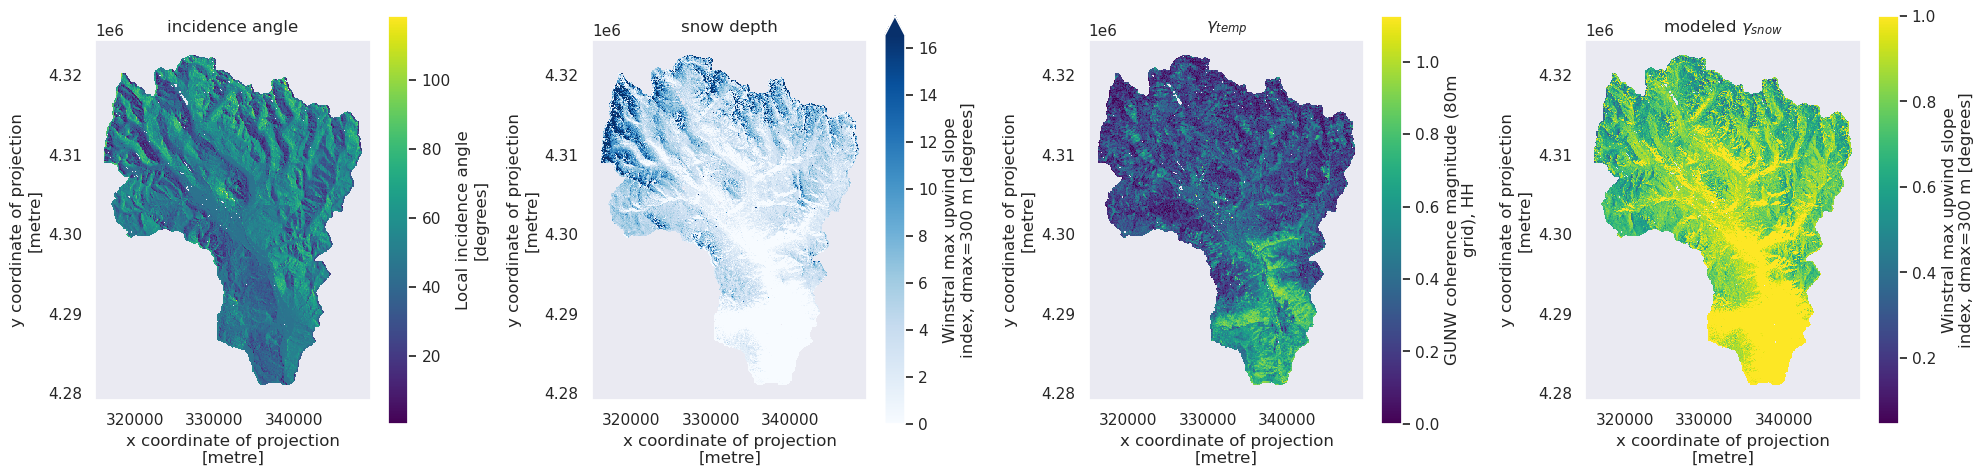

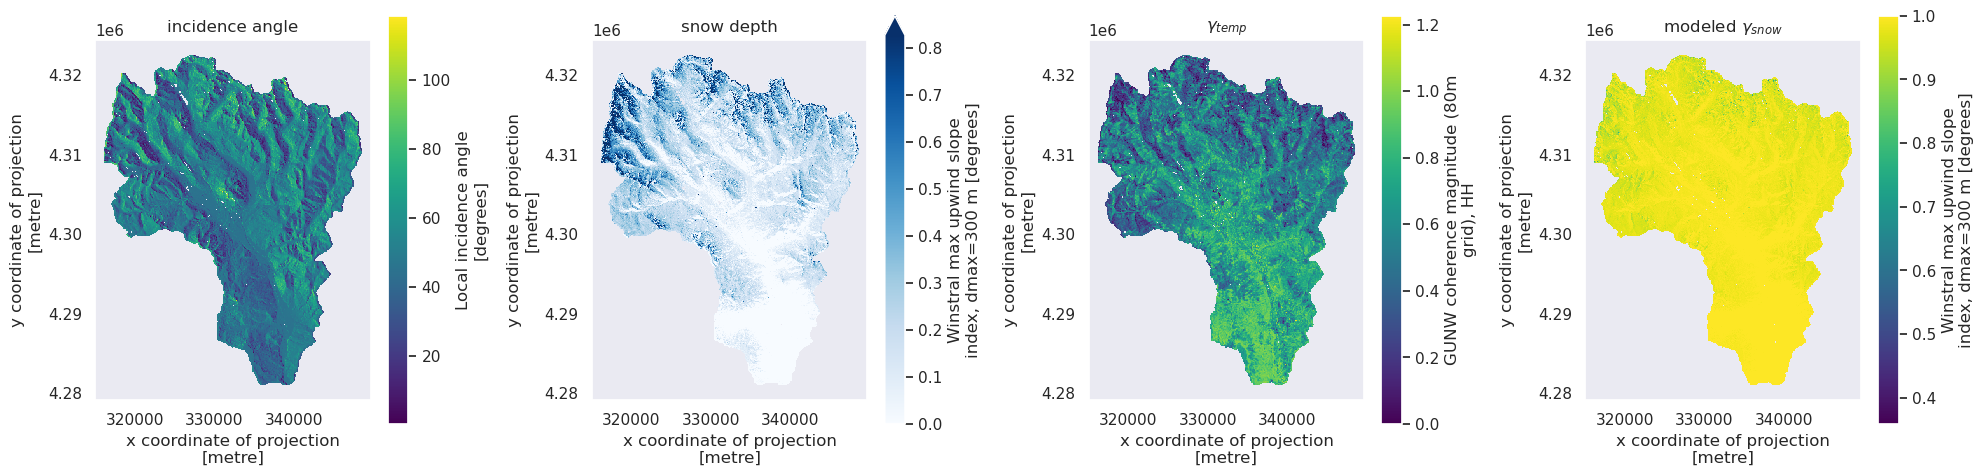

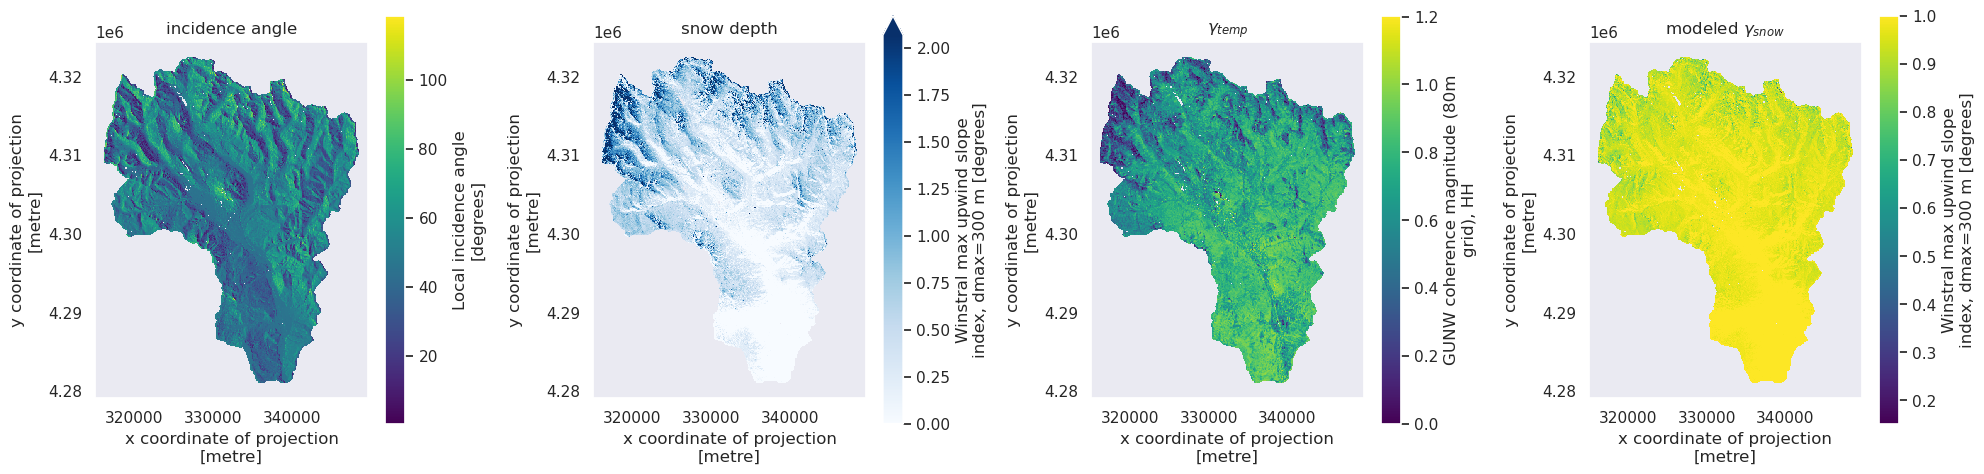

In [225]:
for p in decor.pair.values: 
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    coh['inc'].where(valid).plot(ax=axes[0])
    axes[0].set_title('incidence angle')

    coh['swe'].sel(pair=p).where(valid).plot(ax=axes[1], robust=True, cmap='Blues')
    axes[1].set_title('snow depth')

    coh['gamma_temporal'].sel(pair=p).where(valid).plot(ax=axes[2])
    axes[2].set_title(r'$\gamma_{temp}$')

    decor.sel(pair=p).plot(ax=axes[3])
    axes[3].set_title(r'modeled $\gamma_{snow}$')

    for ax in axes: 
        ax.set_aspect('equal')

    plt.tight_layout()
    plt.show()

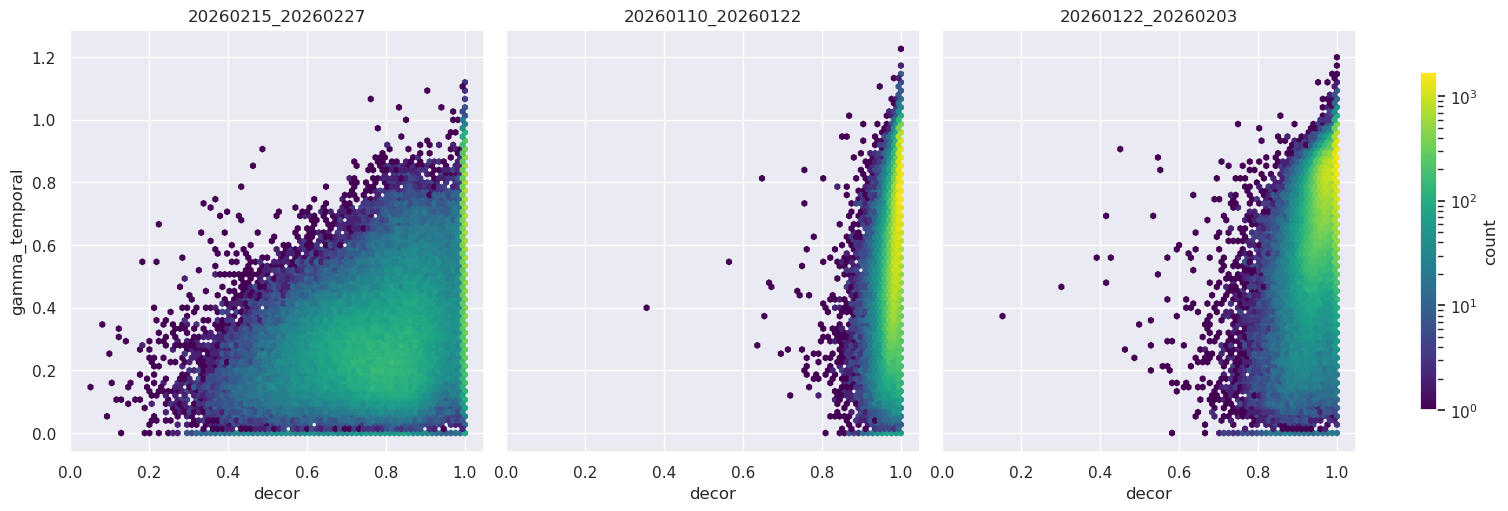

In [226]:
from matplotlib.colors import LogNorm

pairs = decor.pair.values
fig, axes = plt.subplots(1, len(pairs), figsize=(15, 5),
                         sharex=True, sharey=True, constrained_layout=True)

# Flatten and drop NaNs per pair
data = []
for p in pairs:
    x = decor.sel(pair=p).values.ravel()
    y = coh['gamma_temporal'].sel(pair=p).values.ravel()
    m = np.isfinite(x) & np.isfinite(y)
    data.append((x[m], y[m]))

# Shared color scale across panels (computed from the actual bin counts)
xlim = (min(d[0].min() for d in data), max(d[0].max() for d in data))
ylim = (min(d[1].min() for d in data), max(d[1].max() for d in data))
gridsize = 80

vmax = 0
for x, y in data:
    h = plt.hexbin(x, y, gridsize=gridsize, extent=(*xlim, *ylim))
    vmax = max(vmax, h.get_array().max())
    h.remove()

for ax, p, (x, y) in zip(axes, pairs, data):
    hb = ax.hexbin(x, y, gridsize=gridsize, extent=(*xlim, *ylim),
                   norm=LogNorm(vmin=1, vmax=vmax), mincnt=1, cmap='viridis')
    ax.set_title(str(p))
    ax.set_xlabel('decor')
axes[0].set_ylabel('gamma_temporal')

fig.colorbar(hb, ax=axes, label='count', shrink=0.8)
plt.show()